# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the game-day sample. Each one is graded against the six-point rubric from Wednesday's studio, so score your own before you submit.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart also needs a one-line caption below it saying what decision it supports. A chart that supports no decision does not belong in the notebook.

In [1]:
import pandas as pd, numpy as np
rng = np.random.default_rng(11)
df = pd.DataFrame({
    'hour': rng.integers(9,22,800),
    'zone': rng.choice(['A','B','C'],800,p=[.6,.3,.1]),
    'category': rng.choice(['Food','Merch','RainGear','Drink'],800,p=[.5,.2,.1,.2]),
    'revenue': rng.uniform(3,25,800).round(2),
})
df.head()

,hour,zone,category,revenue
0,10,A,Drink,11.12
1,10,B,Food,17.40
2,19,A,Food,24.40
3,15,A,Food,19.94
4,16,A,Food,7.82


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

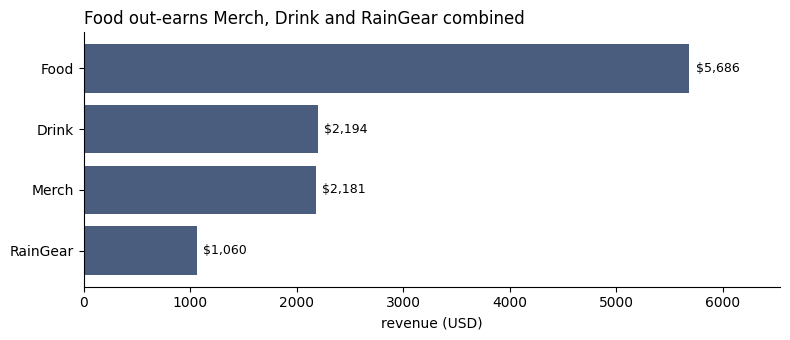

In [2]:
import matplotlib.pyplot as plt

# drop the top/right spines on every chart in this notebook
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

cat_rev = df.groupby('category')['revenue'].sum().sort_values()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(cat_rev.index, cat_rev.values, color='#4a5d7e')
ax.set_xlim(0, cat_rev.max() * 1.15)
ax.set_title('Food out-earns Merch, Drink and RainGear combined', loc='left', fontsize=12)
ax.set_xlabel('revenue (USD)')
for y, v in enumerate(cat_rev.values):
    ax.text(v + 60, y, f'${v:,.0f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

**Caption:** Food is 51% of revenue, so Food lines get first call on staff and stock — losing Food would cost more than losing the other three categories together.

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

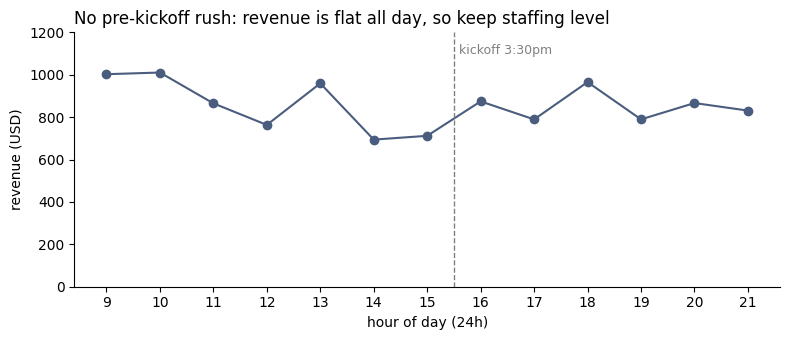

In [3]:
hourly_rev = df.groupby('hour')['revenue'].sum()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(hourly_rev.index, hourly_rev.values, marker='o', color='#4a5d7e')
ax.axvline(15.5, ls='--', color='gray', lw=1)
ax.text(15.6, 1100, 'kickoff 3:30pm', fontsize=9, color='gray')
ax.set_ylim(0, 1200)
ax.set_xticks(hourly_rev.index)
ax.set_title('No pre-kickoff rush: revenue is flat all day, so keep staffing level', loc='left', fontsize=12)
ax.set_xlabel('hour of day (24h)')
ax.set_ylabel('revenue (USD)')
plt.tight_layout()
plt.show()

**Caption:** Supports the shift schedule — revenue stays between roughly \$700 and \$1,000 every hour, so no surge crew before kickoff; 2–4pm (the two slowest hours) is the best window for breaks.

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

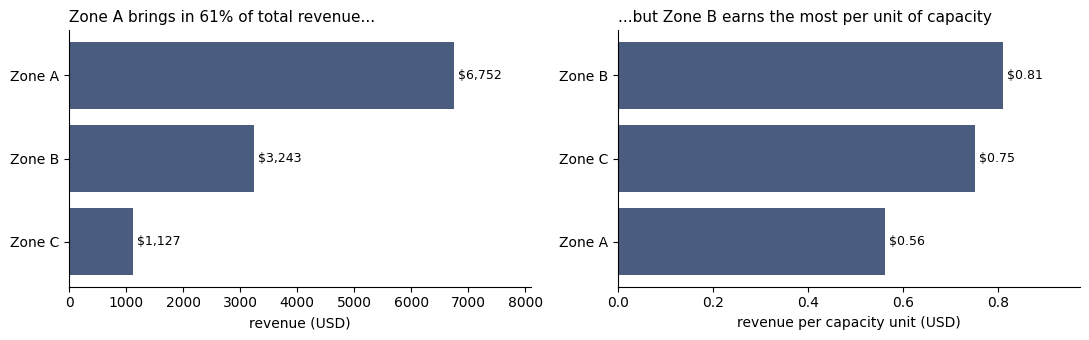

In [4]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}

zone_rev = df.groupby('zone')['revenue'].sum()
zone_rev_per_cap = zone_rev / pd.Series(zone_capacity)

panels = [
    (zone_rev, 'Zone A brings in 61% of total revenue...', 'revenue (USD)', '${:,.0f}'),
    (zone_rev_per_cap, '...but Zone B earns the most per unit of capacity',
     'revenue per capacity unit (USD)', '${:.2f}'),
]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (series, title, xlabel, fmt) in zip(axes, panels):
    s = series.sort_values()
    ax.barh('Zone ' + s.index, s.values, color='#4a5d7e')
    ax.set_xlim(0, s.max() * 1.2)
    ax.set_title(title, loc='left', fontsize=11)
    ax.set_xlabel(xlabel)
    for y, v in enumerate(s.values):
        ax.text(v + s.max() * 0.01, y, fmt.format(v), va='center', fontsize=9)
plt.tight_layout()
plt.show()

**Caption, and which panel I would present:** The left panel answers "where is our money?" and the right panel answers "which zone earns the most for its size?" I would put the **right (per-capacity) panel** in front of a manager deciding where the next cart or staff member goes: Zone B earns \$0.81 per unit of capacity vs. Zone A's \$0.56 (44% more), so Zone B gets the next cart.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

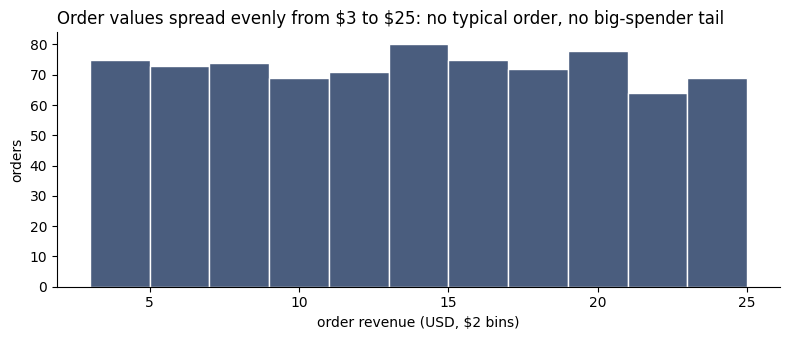

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df['revenue'], bins=np.arange(3, 27, 2), color='#4a5d7e', edgecolor='white')
ax.set_title(r'Order values spread evenly from \$3 to \$25: no typical order, no big-spender tail',
             loc='left', fontsize=12)
ax.set_xlabel('order revenue (USD, $2 bins)')
ax.set_ylabel('orders')
plt.tight_layout()
plt.show()

**Caption:** The shape is flat — every \$2 band from \$3 to \$25 holds about the same number of orders (mean ≈ median ≈ \$13.90), so there is no common basket size and no tail of big orders, which a category total cannot show. Decision: grow revenue by moving more orders through the line (faster service, more points of sale), not by chasing big-ticket buyers.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

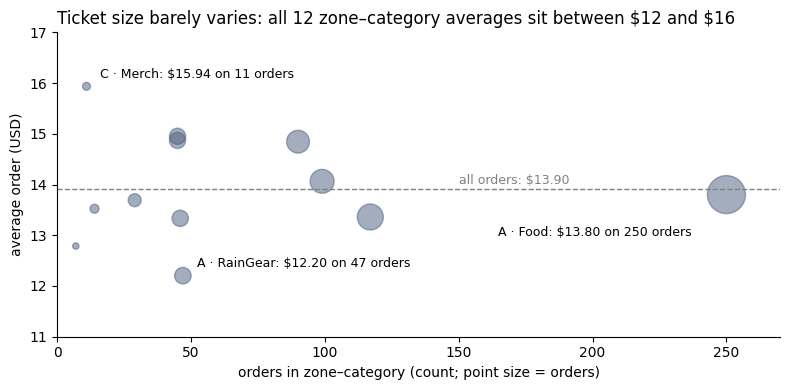

In [6]:
cell_stats = (df.groupby(['zone', 'category'])['revenue']
                .agg(orders='size', avg_order='mean')
                .reset_index())
overall_avg = df['revenue'].mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(cell_stats['orders'], cell_stats['avg_order'],
           s=cell_stats['orders'] * 3, alpha=0.5, color='#4a5d7e')
ax.axhline(overall_avg, ls='--', color='gray', lw=1)
ax.text(150, overall_avg + 0.1, f'all orders: ${overall_avg:.2f}', fontsize=9, color='gray')

# label the highest, lowest, and best-supported averages with their order counts
for i in {cell_stats['avg_order'].idxmax(), cell_stats['avg_order'].idxmin(), cell_stats['orders'].idxmax()}:
    r = cell_stats.loc[i]
    is_rightmost = r.orders == cell_stats['orders'].max()
    ax.annotate(f'{r.zone} · {r.category}: ${r.avg_order:.2f} on {r.orders} orders',
                (r.orders, r.avg_order), xytext=(-25, -30) if is_rightmost else (10, 6),
                textcoords='offset points', ha='right' if is_rightmost else 'left', fontsize=9)

ax.set_xlim(0, 270)
ax.set_ylim(11, 17)
ax.set_title(r'Ticket size barely varies: all 12 zone–category averages sit between \$12 and \$16',
             loc='left', fontsize=12)
ax.set_xlabel('orders in zone–category (count; point size = orders)')
ax.set_ylabel('average order (USD)')
plt.tight_layout()
plt.show()

**Caption:** Supports pricing and promotions — don't set zone- or category-specific prices off average-ticket gaps. The highest average (C · Merch, \$15.94) rests on just 11 orders, while the three biggest cells (99–250 orders) all sit within \$0.55 of the \$13.90 overall average.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [7]:
scores = {
    'chart 1 (category)': 6,
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 6,
    'chart 4 (distribution)': 6,
    'chart 5 (your choice)': 6,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      6/6  [ok]

average: 6.0/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

**a)** Chart 2 changed my mind. I expected the pre-kickoff spike from the lecture example, but revenue is flat all day and 2–4pm is actually the slowest stretch, so the staff up before kickoff, plan isn't supported by this data. It was also the hardest to title, because the finding is that nothing happens.

**b)** Raw revenue is the right view when the question is about where the money is. Budgeting, cash handling, inventory volume, or reporting totals to ownership. There, Zone A's 61% share is what matters. Revenue per unit of capacity is the right view when comparing how well different-sized zones perform. Zone B leads at \$0.81 per unit vs. Zone A's \$0.56.